# EDA: YouTube Title-Thumbnail Success Prediction

Exploratory analysis of the prepared data (`data/split.csv`, `data/features.csv`, `data/image_features.csv`).

- **Target:** `y = log(day19 / subscribers)`, the log of views after 20 days relative to channel size.
- Run this notebook from the repo root or from `notebooks/`. Figures are saved to `figures/`.
- Set `THUMBS_DIR` in the first cell to also get the thumbnail examples (the images are not in the repo; they are in the Kaggle dataset).

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from scipy.stats import gaussian_kde
from IPython.display import display

# ---- paths ----
for p in [Path("data"), Path("../data")]:
    if (p / "split.csv").exists():
        DATA_DIR = p
        break
else:
    raise FileNotFoundError("data/split.csv not found. Run the notebook from the repo root or from notebooks/.")

THUMBS_DIR = None   # e.g. Path("thumbs") or the Kaggle thumbnails folder. None = skip the thumbnail examples
FIG_DIR = DATA_DIR.parent / "figures"
FIG_DIR.mkdir(exist_ok=True)

# ---- style: validated categorical slots 1-3, one-hue blue ramp for density, recessive chrome ----
C = dict(surface="#ffffff", text="#191919", text2="#666666", grid="#e7e7e7", axis="#c2c2c2",
         s1="#257de0", s2="#f47230", s3="#00b894")
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "font.family": "sans-serif", "font.size": 10, "text.color": C["text"],
    "axes.edgecolor": C["axis"], "axes.labelcolor": C["text2"], "axes.titlecolor": C["text"],
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": C["text2"], "ytick.color": C["text2"],
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 1, "axes.axisbelow": True,
    "legend.frameon": False,
})
BLUE_RAMP = LinearSegmentedColormap.from_list("blue", ["#cce3fd", "#84b9f3", "#338ced", "#1b64be", "#0e3d7e"])

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

In [3]:
split = pd.read_csv(DATA_DIR / "split.csv")
feat = pd.read_csv(DATA_DIR / "features.csv")
img = pd.read_csv(DATA_DIR / "image_features.csv")
df = split.merge(feat, on="video_id").merge(img.drop(columns=["read_ok"]), on="video_id")
df["has_face"] = (df.n_faces > 0).astype(int)
df["y_c"] = df.y - df.groupby("channel_title").y.transform("mean")   # y relative to the channel's own mean

print(f"{len(df):,} videos, {df.channel_title.nunique():,} channels, {df.category.nunique()} categories")
display(df.groupby("split").size().rename("videos").to_frame())

24,477 videos, 11,505 channels, 15 categories


,videos
split,
test,2448
train,19580
val,2449


## 1. Distribution of the target

Left: all videos. Right: the three splits, which should have (almost) the same distribution.

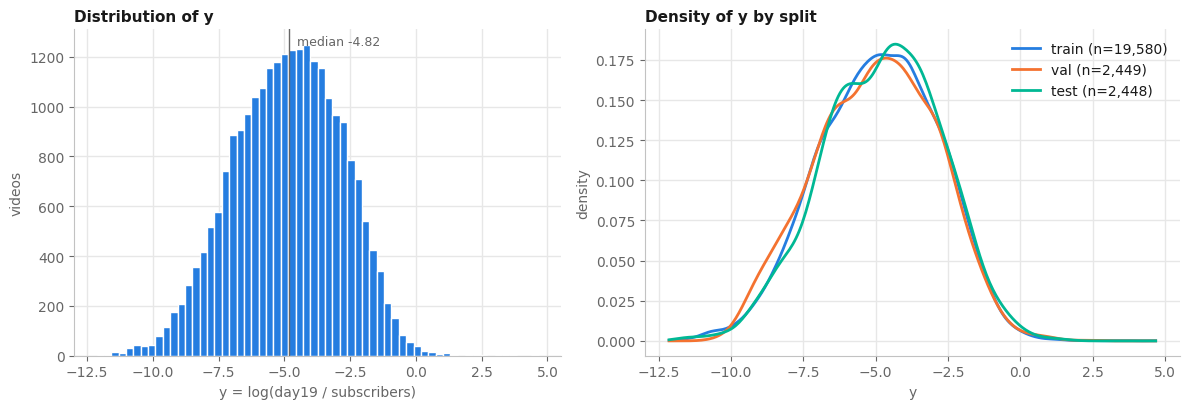

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,2448.0,-4.78,2.03,-11.81,-6.19,-4.66,-3.33,1.45
train,19580.0,-4.89,2.06,-12.14,-6.34,-4.83,-3.39,4.67
val,2449.0,-4.98,2.07,-10.41,-6.46,-4.91,-3.45,2.28


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})

ax1.hist(df.y, bins=60, color=C["s1"], edgecolor=C["surface"], linewidth=1)
med = df.y.median()
ax1.axvline(med, color=C["text2"], lw=1)
ax1.annotate(f"median {med:.2f}", (med, ax1.get_ylim()[1]), xytext=(6, -4), textcoords="offset points",
             va="top", color=C["text2"], fontsize=9)
ax1.set_title("Distribution of y")
ax1.set_xlabel("y = log(day19 / subscribers)")
ax1.set_ylabel("videos")

xs = np.linspace(df.y.min(), df.y.max(), 300)
for name, col in zip(["train", "val", "test"], [C["s1"], C["s2"], C["s3"]]):
    v = df.loc[df.split == name, "y"]
    ax2.plot(xs, gaussian_kde(v)(xs), color=col, lw=2, label=f"{name} (n={len(v):,})")
ax2.set_title("Density of y by split")
ax2.set_xlabel("y")
ax2.set_ylabel("density")
ax2.legend()
fig.tight_layout()
save(fig, "01_y_distribution")
plt.show()

display(df.groupby("split").y.describe().round(2))

## 2. Success by category

Dot = median `y`, line = interquartile range. Categories are sorted by median.

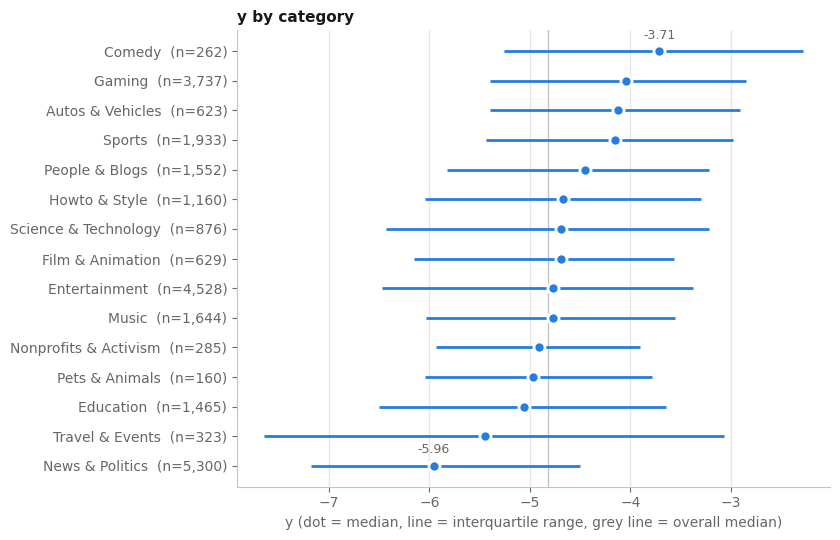

,med,q1,q3,n
category,,,,
News & Politics,-5.96,-7.18,-4.50,5300
Travel & Events,-5.45,-7.65,-3.07,323
Education,-5.06,-6.50,-3.65,1465
Pets & Animals,-4.97,-6.04,-3.78,160
Nonprofits & Activism,-4.91,-5.94,-3.90,285
Music,-4.77,-6.03,-3.55,1644
Entertainment,-4.77,-6.48,-3.37,4528
Film & Animation,-4.69,-6.15,-3.56,629
Science & Technology,-4.69,-6.43,-3.22,876


In [5]:
g = df.groupby("category").y.agg(med="median", q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75), n="size").sort_values("med")
fig, ax = plt.subplots(figsize=(8.5, 5.5))
yy = np.arange(len(g))
ax.axvline(df.y.median(), color=C["axis"], lw=1)
ax.hlines(yy, g.q1, g.q3, color=C["s1"], lw=2)
ax.plot(g.med, yy, "o", ms=8, color=C["s1"], mec=C["surface"], mew=2)
ax.set_yticks(yy, [f"{c}  (n={n:,})" for c, n in zip(g.index, g.n)])
ax.grid(axis="y", visible=False)
for i in (0, len(g) - 1):   # label only the extremes
    ax.annotate(f"{g.med.iloc[i]:.2f}", (g.med.iloc[i], i), xytext=(0, 9), textcoords="offset points",
                ha="center", color=C["text2"], fontsize=9)
ax.set_xlabel("y (dot = median, line = interquartile range, grey line = overall median)")
ax.set_title("y by category")
fig.tight_layout()
save(fig, "02_y_by_category")
plt.show()

display(g.round(2))

## 3. Success vs channel size and video length

Each hexagon counts videos (darker = more). The orange line is the median `y` in 20 equal-sized bins of the x variable.

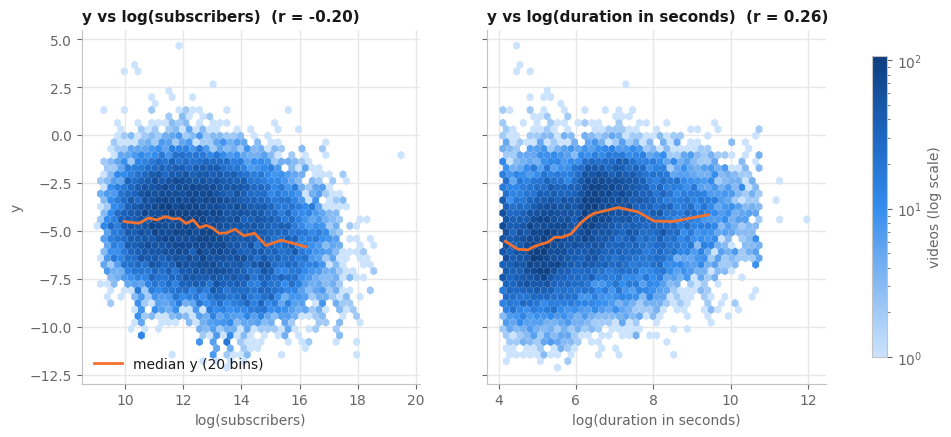

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, col, lab in zip(axes, ["log_subscribers", "log_duration"], ["log(subscribers)", "log(duration in seconds)"]):
    hb = ax.hexbin(df[col], df.y, gridsize=45, cmap=BLUE_RAMP, mincnt=1, norm=LogNorm(), linewidths=0)
    b = pd.qcut(df[col], 20, duplicates="drop")
    m = df.groupby(b, observed=True).agg(x=(col, "median"), y=("y", "median"))
    ax.plot(m.x, m.y, color=C["s2"], lw=2, label="median y (20 bins)")
    r = df[[col, "y"]].corr().iloc[0, 1]
    ax.set_title(f"y vs {lab}  (r = {r:.2f})")
    ax.set_xlabel(lab)
axes[0].set_ylabel("y")
axes[0].legend(loc="lower left")
fig.colorbar(hb, ax=axes, label="videos (log scale)", shrink=0.85)
save(fig, "03_y_vs_subscribers_duration")
plt.show()

## 4. Text and faces on the thumbnail: between channels vs within a channel

Difference in mean `y` between thumbnails with and without the feature, with approximate 95% confidence intervals.

- **all videos**: compares all videos with and without the feature.
- **within the same channel**: only channels with several videos where the feature changes between videos; `y` is measured relative to the channel's own mean, so channel style cancels out.

If the effect is large in the first comparison but near zero in the second, the feature mainly marks *which channels* use it, not an effect of the thumbnail itself.

,feature,comparison,diff,ci95,n
0,Text on thumbnail,all videos,0.330,0.053,24477
1,Text on thumbnail,within the same channel,0.038,0.048,8917
2,Face on thumbnail,all videos,0.116,0.054,24477
3,Face on thumbnail,within the same channel,0.068,0.045,10365


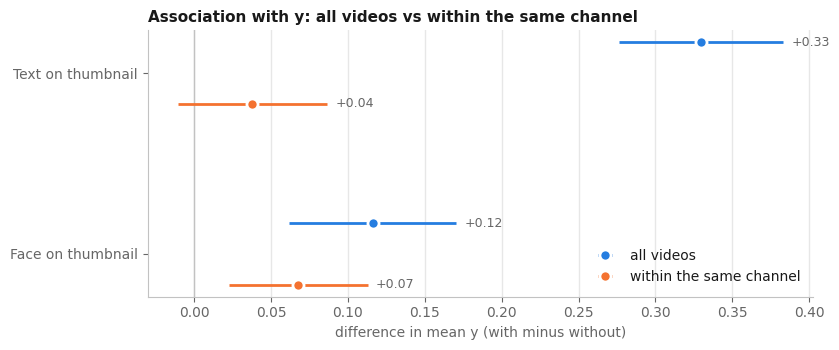

In [7]:
def diff(a, b):
    d = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return d, 1.96 * se

multi = df.groupby("channel_title").video_id.transform("size") > 1
rows = []
for col, label in [("has_text", "Text on thumbnail"), ("has_face", "Face on thumbnail")]:
    a, b = df[df[col] == 1].y, df[df[col] == 0].y
    rows.append((label, "all videos", *diff(a, b), len(a) + len(b)))
    varies = df.groupby("channel_title")[col].transform("nunique") > 1
    w = df[multi & varies]
    a, b = w[w[col] == 1].y_c, w[w[col] == 0].y_c
    rows.append((label, "within the same channel", *diff(a, b), len(w)))
res = pd.DataFrame(rows, columns=["feature", "comparison", "diff", "ci95", "n"])
display(res.round(3))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
colors = {"all videos": C["s1"], "within the same channel": C["s2"]}
offsets = {"all videos": -0.17, "within the same channel": 0.17}
base = {"Text on thumbnail": 0, "Face on thumbnail": 1}
ax.axvline(0, color=C["axis"], lw=1)
for comp in colors:
    r = res[res.comparison == comp]
    pos = [base[f] + offsets[comp] for f in r.feature]
    ax.errorbar(r["diff"], pos, xerr=r.ci95, fmt="o", ms=8, color=colors[comp], mec=C["surface"], mew=2,
                lw=2, capsize=0, label=comp)
    for d, ci, p in zip(r["diff"], r.ci95, pos):
        ax.annotate(f"{d:+.2f}" if abs(d) >= 0.005 else "0.00", (d + ci, p), xytext=(6, 0), textcoords="offset points", va="center",
                    color=C["text2"], fontsize=9)
ax.set_yticks(list(base.values()), list(base.keys()))
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("difference in mean y (with minus without)")
ax.set_title("Association with y: all videos vs within the same channel")
ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "04_text_face_between_vs_within")
plt.show()

Intervals are approximate: videos from the same channel are not independent, so the real uncertainty is somewhat larger.

## 5. Facial emotion (videos with a face only)

Dominant emotion of the largest face. Left: mean `y`. Right: mean `y` relative to the channel's own mean (only channels with several face videos). Hollow markers = fewer than 100 videos.

all face videos       within channel      
                    mean     n           mean     n
dominant                                           
sad               -5.063  1280         -0.023   852
angry             -4.886  1014         -0.040   667
neutral           -4.844  2514          0.016  1573
disgust           -4.827    25          0.038    16
happy             -4.798  2558         -0.008  1465
fear              -4.670   851          0.035   489
surprise          -3.975   370          0.084   172

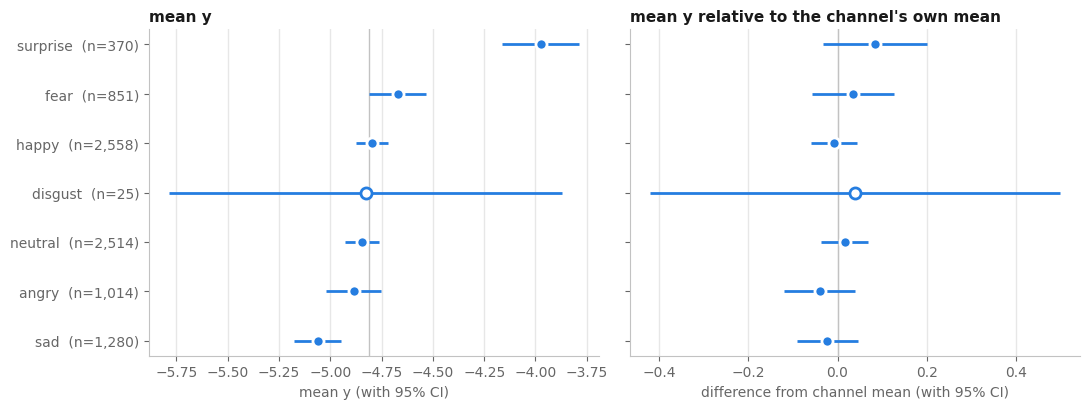

In [8]:
emo = [c for c in df.columns if c.startswith("emo_")]
f = df[df.n_faces > 0].copy()
f["dominant"] = f[emo].idxmax(axis=1).str.replace("emo_", "")
f["n_ch"] = f.groupby("channel_title").video_id.transform("size")
f["y_cf"] = f.y - f.groupby("channel_title").y.transform("mean")

def stats(frame, col):
    g = frame.groupby("dominant")[col].agg(mean="mean", sd="std", n="size")
    g["ci"] = 1.96 * g.sd / np.sqrt(g.n)
    return g

g1 = stats(f, "y")
g2 = stats(f[f.n_ch > 1], "y_cf")
order = g1.sort_values("mean").index
g1, g2 = g1.loc[order], g2.reindex(order)
display(pd.concat({"all face videos": g1[["mean", "n"]], "within channel": g2[["mean", "n"]]}, axis=1).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
yy = np.arange(len(order))
for ax, g, title in zip(axes, [g1, g2], ["mean y", "mean y relative to the channel's own mean"]):
    ax.axvline(0 if "relative" in title else f.y.mean(), color=C["axis"], lw=1)
    for i, (k, r) in enumerate(g.iterrows()):
        hollow = r.n < 100
        ax.errorbar(r["mean"], i, xerr=r.ci, fmt="o", ms=8, color=C["s1"], lw=2,
                    mfc=C["surface"] if hollow else C["s1"], mec=C["s1"] if hollow else C["surface"], mew=2)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(yy, [f"{k}  (n={int(g1.loc[k, 'n']):,})" for k in order])
axes[0].set_xlabel("mean y (with 95% CI)")
axes[1].set_xlabel("difference from channel mean (with 95% CI)")
fig.tight_layout()
save(fig, "05_emotion")
plt.show()

Emotion labels come from a model that is noisy on small 320x180 thumbnails (it probably labels many neutral faces as sad or angry), so treat this as exploratory.

## 6. Example thumbnails (optional)

Random examples from the top 1% and bottom 1% of `y`. Needs `THUMBS_DIR` to point to the folder with `<video_id>.jpg` files.

In [9]:
if THUMBS_DIR is None or not Path(THUMBS_DIR).is_dir():
    print("THUMBS_DIR not set: skipping. Set it in the first cell to see example thumbnails.")
else:
    from PIL import Image
    hi = df[df.y >= df.y.quantile(.99)].sample(6, random_state=0)
    lo = df[df.y <= df.y.quantile(.01)].sample(6, random_state=0)
    fig, axes = plt.subplots(2, 6, figsize=(16, 5.2))
    for axrow, sub, name in zip(axes, [hi, lo], ["Top 1% of y", "Bottom 1% of y"]):
        for ax, (_, r) in zip(axrow, sub.iterrows()):
            ax.imshow(Image.open(Path(THUMBS_DIR) / f"{r.video_id}.jpg"))
            ax.axis("off")
            ax.set_title(f"y = {r.y:.1f}  {r.category}", fontsize=8, color=C["text2"])
        axrow[0].text(-0.05, 0.5, name, transform=axrow[0].transAxes, rotation=90, va="center", ha="right",
                      color=C["text"], fontweight="semibold")
    fig.tight_layout()
    save(fig, "06_thumbnail_examples")
    plt.show()

THUMBS_DIR not set: skipping. Set it in the first cell to see example thumbnails.


## Takeaways for the report

Fill in with the numbers printed above:

1. `y` is roughly symmetric and has the same distribution in train, val and test.
2. Categories differ in median `y`, so the split is stratified by category.
3. The target is only weakly tied to channel size (much weaker than raw views), but `log_subscribers` still carries some signal.
4. Text and faces are associated with higher `y` across channels, but the association almost disappears within a channel: they mostly mark which channels use them, so describe them as *associated with*, not *causing*, success.
5. Emotion features are weak and exploratory.